## K-Means Assignment



### 1. Understanding the Elbow Method

Generate a sample dataset, apply K-Means for K = 1 to 10, plot WCSS, and identify the approximate optimal number of clusters.



In [1]:
lazy import numpy as np
lazy import pandas as pd
lazy import matplotlib.pyplot as plt
lazy import seaborn as sns
lazy from sklearn.datasets import make_blobs
lazy from sklearn.preprocessing import StandardScaler
lazy from sklearn.cluster import KMeans
lazy from sklearn.metrics import silhouette_score


Dataset shape: (500, 2)


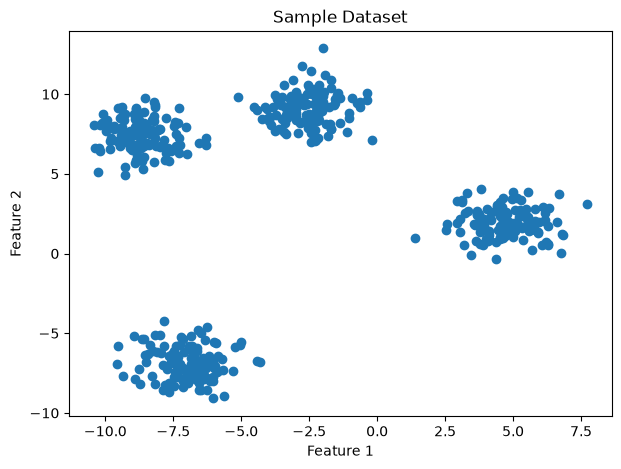

In [2]:
X, y = make_blobs(
    n_samples=500,
    centers=4,
    n_features=2,
    cluster_std=1.0,
    random_state=42
)

print("Dataset shape:", X.shape)
plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1])
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Sample Dataset")
plt.show()


In [3]:
wcss = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

print("WCSS values:", wcss)


WCSS values: [33903.904151021066, 15737.083577865002, 3426.257238005966, 948.8903433376543, 856.4718894933583, 768.0389975161893, 681.3515378883386, 608.5380315867329, 546.7905974806384, 497.9914856590418]


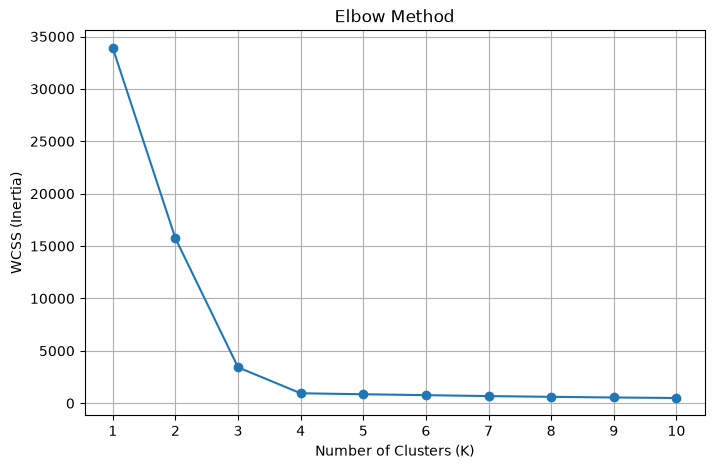

In [4]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS (Inertia)")
plt.title("Elbow Method")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()


**Observation:** The elbow is expected around K = 4 because the generated dataset contains four underlying groups. Confirm the exact bend from the plotted curve.

**Why WCSS decreases:** WCSS is the sum of squared distances between each point and its assigned centroid. Increasing K gives K-Means more centroids, so points can be assigned to closer centroids and WCSS cannot increase for an optimally fitted solution. If every point is its own cluster, WCSS is 0. The goal is to find a useful elbow before adding clusters gives only small improvements.



### 2. Effect of Feature Scaling

Create Age and Annual Income features with different ranges, then compare K-Means before and after `StandardScaler`.



In [5]:
np.random.seed(42)

df = pd.DataFrame({
    "Age": np.random.uniform(18, 60, 500).astype(int),
    "Annual Income": np.random.uniform(20000, 200000, 500).astype(int)
})

df.head()


,Age,Annual Income
0,33,145669
1,57,116497
2,48,75714
3,43,166483
4,24,143251


In [6]:
                        
kmeans_raw = KMeans(n_clusters=3, random_state=42, n_init=10)
df["Cluster Before Scaling"] = kmeans_raw.fit_predict(df[["Age", "Annual Income"]])

                           
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[["Age", "Annual Income"]])

                       
kmeans_scaled = KMeans(n_clusters=3, random_state=42, n_init=10)
df["Cluster After Scaling"] = kmeans_scaled.fit_predict(X_scaled)

print("WCSS before scaling:", kmeans_raw.inertia_)
print("WCSS after scaling:", kmeans_scaled.inertia_)


WCSS before scaling: 138471265539.0967
WCSS after scaling: 373.4993920390426


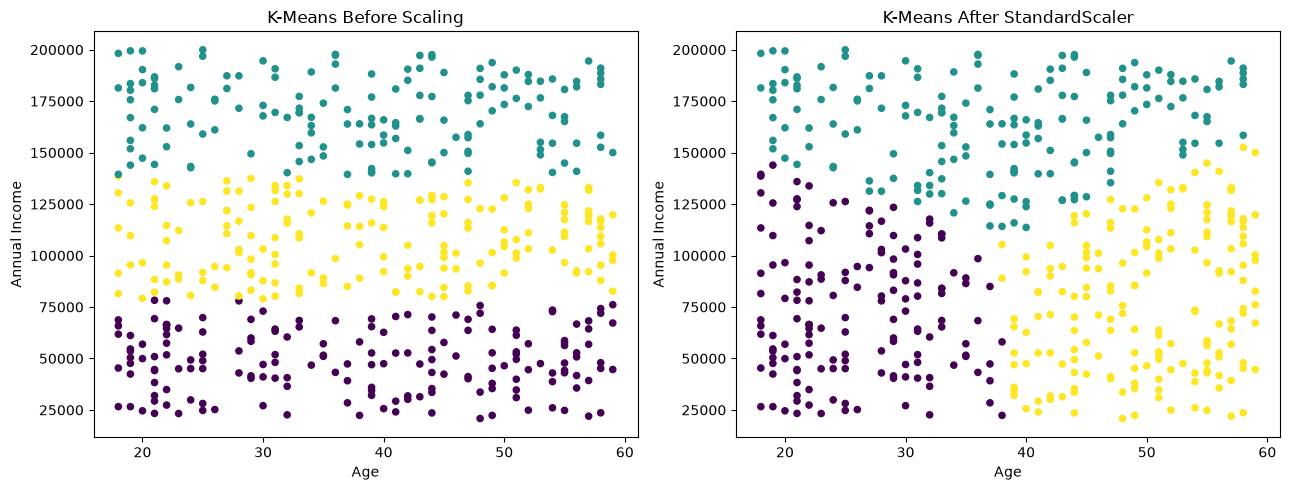

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(df["Age"], df["Annual Income"],
                c=df["Cluster Before Scaling"], cmap="viridis", s=20)
axes[0].set_title("K-Means Before Scaling")
axes[0].set_xlabel("Age")
axes[0].set_ylabel("Annual Income")

axes[1].scatter(df["Age"], df["Annual Income"],
                c=df["Cluster After Scaling"], cmap="viridis", s=20)
axes[1].set_title("K-Means After StandardScaler")
axes[1].set_xlabel("Age")
axes[1].set_ylabel("Annual Income")

plt.tight_layout()
plt.show()


**Observation:** Before scaling, Annual Income has values in the tens or hundreds of thousands, while Age ranges only from 18 to 60. Since K-Means uses Euclidean distance, income can dominate the distance calculation. `StandardScaler` transforms each feature to have approximately mean 0 and standard deviation 1, giving Age and Income more comparable influence. Cluster labels are arbitrary, so label numbers should not be compared directly; compare the groupings instead.



### 3. Effect of Choosing Different K Values

Use the same Age and Annual Income dataset after scaling. Fit K-Means with K = 2, 3, 4, and 5, visualize the clusters, and compare WCSS.



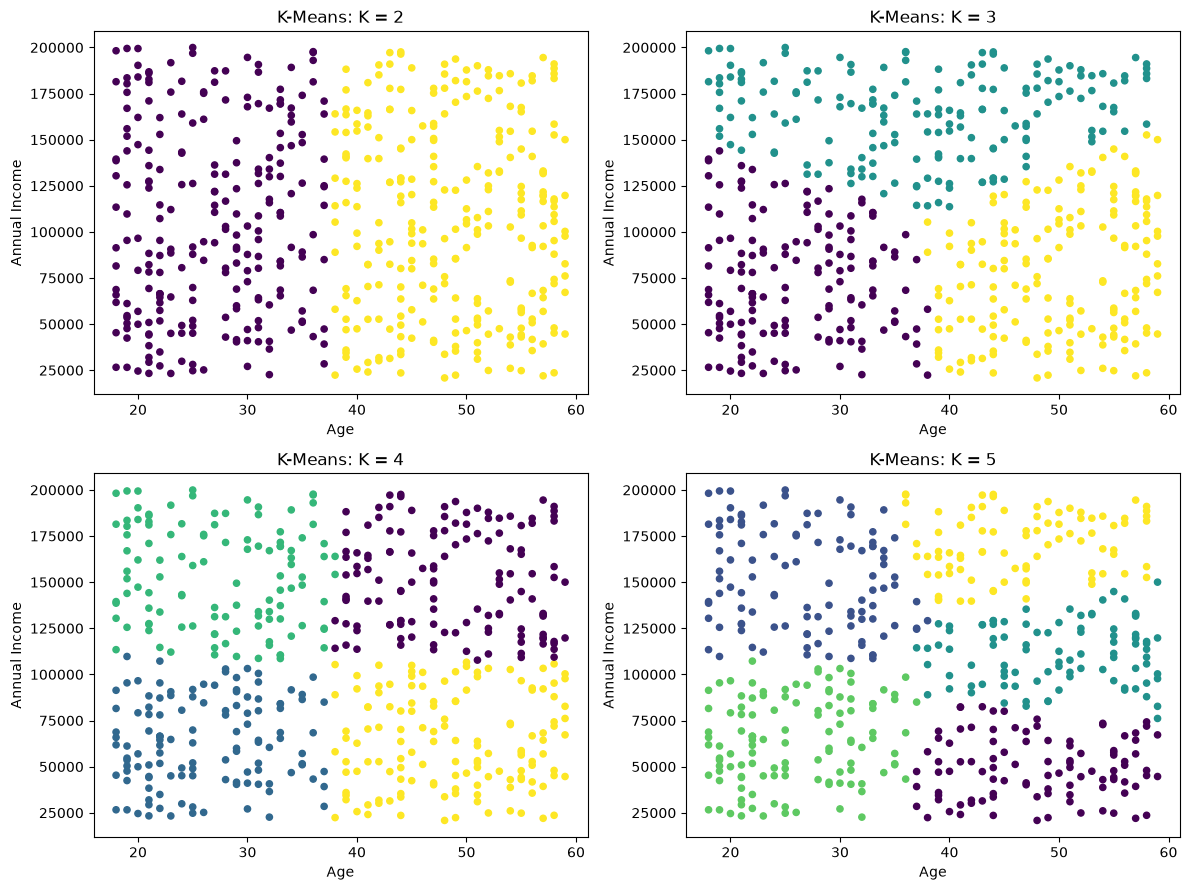

K = 2: WCSS = 619.60
K = 3: WCSS = 373.50
K = 4: WCSS = 244.29
K = 5: WCSS = 200.60


In [8]:
k_values = [2, 3, 4, 5]
wcss_by_k = {}

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes = axes.ravel()

for ax, k in zip(axes, k_values):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    wcss_by_k[k] = model.inertia_

    ax.scatter(df["Age"], df["Annual Income"], c=labels, cmap="viridis", s=20)
    ax.set_title(f"K-Means: K = {k}")
    ax.set_xlabel("Age")
    ax.set_ylabel("Annual Income")

plt.tight_layout()
plt.show()

for k, value in wcss_by_k.items():
    print(f"K = {k}: WCSS = {value:.2f}")


**Explanation:** As K increases from 2 to 5, WCSS should decrease. If K is too small, different natural groups may be merged. If K is too large, a natural group may be split into several smaller clusters, making the model more complex without necessarily providing useful extra information. WCSS alone always favors more clusters, so use the elbow curve and domain context as well.



### 4. Understanding Cluster Centroids

Generate three distinct groups, fit K-Means with K = 3, display the centroids, and plot them with the data points.



In [9]:
X_centroid, y_centroid = make_blobs(
    n_samples=450,
    centers=[(-5, -5), (0, 5), (5, -2)],
    cluster_std=0.8,
    n_features=2,
    random_state=42
)

kmeans_3 = KMeans(n_clusters=3, random_state=42, n_init=10)
labels_3 = kmeans_3.fit_predict(X_centroid)
centroids = kmeans_3.cluster_centers_

print("Cluster centroids:")
print(centroids)


Cluster centroids:
[[ 5.02826829 -1.8967577 ]
 [ 0.00999358  4.95562245]
 [-5.02724847 -4.98162923]]


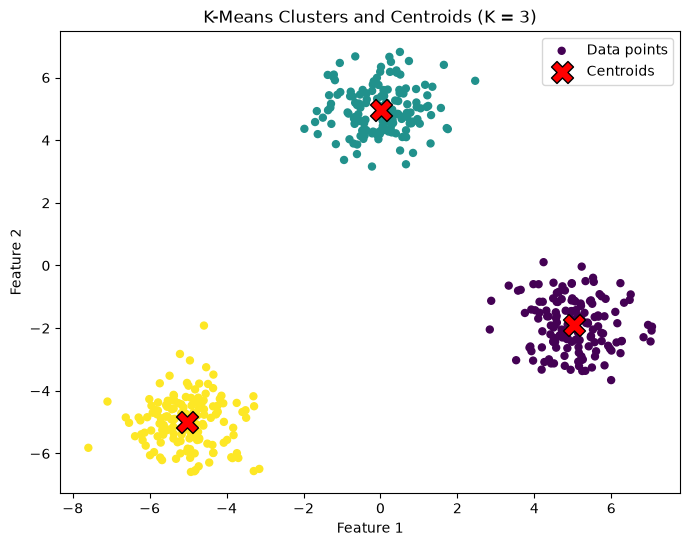

In [10]:
plt.figure(figsize=(8, 6))
plt.scatter(X_centroid[:, 0], X_centroid[:, 1],
            c=labels_3, cmap="viridis", s=25, label="Data points")
plt.scatter(centroids[:, 0], centroids[:, 1],
            marker="X", s=250, color="red", edgecolor="black",
            label="Centroids")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("K-Means Clusters and Centroids (K = 3)")
plt.legend()
plt.show()


**Explanation:** A centroid is the mean position of all points assigned to a cluster. For each feature, K-Means calculates the average value of that feature among the points in the cluster. During fitting, K-Means assigns each point to its nearest centroid, recalculates each centroid as the mean of its assigned points, and repeats these steps until assignments/centroids stop changing significantly or the iteration limit is reached.



### 5. Evaluating Clustering Performance

Use WCSS (Elbow Method) and Silhouette Score to help choose a suitable number of clusters.



In [11]:
X_eval, y_eval = make_blobs(
    n_samples=500,
    centers=4,
    n_features=2,
    cluster_std=1.0,
    random_state=42
)

eval_wcss = []
silhouette_scores = []
k_range = range(2, 11)

                                   
for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_eval)
    eval_wcss.append(model.inertia_)

                                        
for k in k_range:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_eval)
    silhouette_scores.append(silhouette_score(X_eval, labels))

best_silhouette_k = list(k_range)[int(np.argmax(silhouette_scores))]
print("K with highest Silhouette Score:", best_silhouette_k)
print("Silhouette Scores:", [round(s, 3) for s in silhouette_scores])


K with highest Silhouette Score: 4
Silhouette Scores: [0.596, 0.761, 0.791, 0.663, 0.561, 0.441, 0.337, 0.347, 0.348]


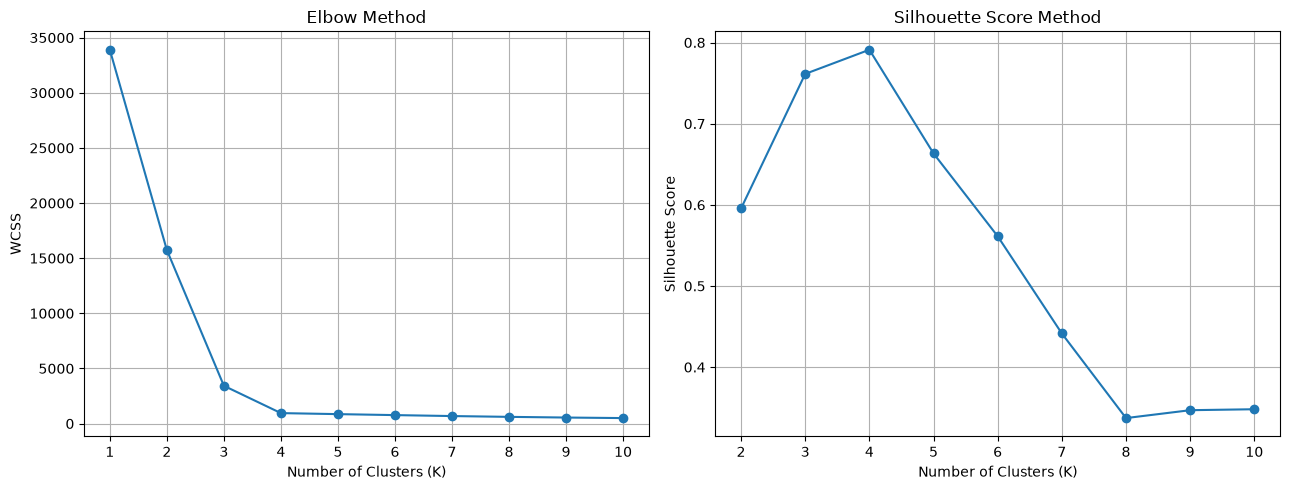

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(range(1, 11), eval_wcss, marker="o")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("WCSS")
axes[0].set_title("Elbow Method")
axes[0].set_xticks(range(1, 11))
axes[0].grid(True)

axes[1].plot(list(k_range), silhouette_scores, marker="o")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_title("Silhouette Score Method")
axes[1].set_xticks(list(k_range))
axes[1].grid(True)

plt.tight_layout()
plt.show()


**Explanation:** The Elbow Method looks for a bend where the reduction in WCSS begins to slow. Another method is the **Silhouette Score**, which measures how close each point is to its own cluster compared with other clusters. Scores range from -1 to 1; higher values generally indicate better-separated clusters. The K with the highest Silhouette Score is a useful candidate, but it should be considered alongside the elbow plot and the data's context. Different methods can suggest different values of K.

